<a href="https://colab.research.google.com/github/yolandazulu/YY_Zulu_22339104-SuppExam/blob/main/YY_Zulu_22339104.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TPRO200 — Supplementary Examination 2026
## A Machine Learning Solution for Identifying Women-Safety Hotspots and Patterns in Ekurhuleni

### My Details
* **Surname & Initials:** Zulu, Y.Y
* **Student Number:** `22339104`
* **Module:** `TLPR200`
* **Interactive Dashboard File:** `app.py` (Streamlit UI)
---

### Data Sources & Direct Hyperlinks
Two independent, factual, and publicly verifiable datasets were sourced from the South African Police Service (SAPS):
1. **Dataset 1 — SAPS Official Quarterly Crime Statistics (2021/22 Q1 to 2026/27 Q1):**
   * **Direct Link:** [https://www.saps.gov.za/services/crimestats.php](https://www.saps.gov.za/services/crimestats.php)
   * **Description:** Five official quarterly Excel workbooks containing station-level crime counts across **21 consecutive quarters** (April 2021 to June 2026) for all **39 official Ekurhuleni District police stations**.
2. **Dataset 2 — SAPS GIS Police Precinct Boundaries & Station Coordinates:**
   * **Direct Link:** [https://www.saps.gov.za/services/boundary.php](https://www.saps.gov.za/services/boundary.php)
   * **Description:** Official polygon shapefiles (`Police_bounds.shp`) and point coordinates (`Police_points.shp`) used to calculate each police precinct's exact land area in square kilometres ($\text{km}^2$), neighbouring station connectivity, and distance to major commercial/transit hubs.

### Responsible Framing for Women-Safety Analytics
* **Honest Crime Labelling:** SAPS station-level spreadsheets do not separate every crime row by victim sex. Therefore, we do **not** falsely relabel general crime statistics as *"crimes against women."* Instead, we analyse six official contact and violent offence categories that directly impact women's bodily safety and public/commuter security: `Sexual Offences`, `Assault GBH`, `Common Assault`, `Murder`, `Aggravated Robbery`, and `Kidnapping`.
* **No Fabricated Media Data:** Recent media-reported cases in Kempton Park and Ekurhuleni motivate this study, but no media stories or speculative victim records are used.
* **Why We Use Spatial Crime Density ($\text{Crimes/km}^2$):** Precinct sizes in Ekurhuleni vary wildly—from compact urban/township stations like **Primrose ($8.95\text{ km}^2$)** and **Tembisa ($14.32\text{ km}^2$)** to huge rural stations like **Devon ($393.01\text{ km}^2$)**. Dividing incident counts by precinct area ($\text{crimes/km}^2$) gives a fair comparison of where risk is spatially concentrated.
* **Non-Stigmatisation:** Calling an area a "hotspot" is strictly a statistical way to guide street lighting, patrol visibility, and victim support—not a claim that a community or its residents are inherently dangerous.

---
# Section 1: Environment Setup & Library Imports
Before loading any data, we set up our Python environment. We split our imports into clear steps so it is easy to see which tools are used for data handling, mapping, plotting, and machine learning.

### 1.1 Importing Core Data & Spatial Libraries
In this cell, we import standard Python libraries for handling file paths (`os`, `glob`, `re`), `numpy` and `pandas` for working with tables of numbers, and `geopandas` for reading geographic map files (shapefiles).

In [47]:
import os
import glob
import re
import json
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd

warnings.filterwarnings('ignore')
print("Core data and spatial libraries imported successfully.")

Core data and spatial libraries imported successfully.


### 1.2 Importing Visualisation Libraries
In this cell, we import `matplotlib` and `seaborn` and set a clean white-grid visual theme so all our charts are easy to read.

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
print("Visualisation libraries (matplotlib and seaborn) configured.")

Visualisation libraries (matplotlib and seaborn) configured.


### 1.3 Importing Machine Learning & Evaluation Libraries
In this cell, we import our classification models (`HistGradientBoostingClassifier`, `RandomForestClassifier`, `LogisticRegression`), clustering algorithm (`KMeans`), data encoders/scalers, and accuracy evaluation metrics from `scikit-learn`.

In [49]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    silhouette_score
)

print("Scikit-learn machine learning and evaluation tools imported.")

Scikit-learn machine learning and evaluation tools imported.


---
# Section 2: Data Acquisition & Loading the SAPS Crime Spreadsheets
In this section, we locate the five official SAPS quarterly Excel files, inspect their internal structure, fix naming inconsistencies, and extract 21 consecutive quarters of crime counts for Ekurhuleni.

### 2.1 Locating the SAPS Quarterly Excel Files
Here we define the folder path (supporting both local execution and Google Colab) and search for all `.xlsx`, `.xls`, and `.xlsm` workbooks so no quarterly file is missed.

In [50]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [51]:
FOLDER_PATH = '.' if os.path.exists('2025-2026_-_1st_Quarter_WEB.xlsx') else '/content/drive/MyDrive/TP2'

excel_files = sorted(
    glob.glob(os.path.join(FOLDER_PATH, '*.xlsx')) +
    glob.glob(os.path.join(FOLDER_PATH, '*.xls')) +
    glob.glob(os.path.join(FOLDER_PATH, '*.xlsm'))
)

print(f"Found {len(excel_files)} SAPS quarterly files:")
for f in excel_files:
    print(" -", os.path.basename(f))

Found 5 SAPS quarterly files:
 - 2025-2026_-_1st_Quarter_WEB.xlsx
 - 2025-2026_-_2nd_Quarter_WEB.xlsx
 - 2025-2026_-_3rd_Quarter_WEB.xlsx
 - 2025-2026_-_4th_Quarter_WEB.xlsx
 - 2026-2027_-_1st_Quarter_WEB.xlsm


### 2.2 Inspecting the Structure of a SAPS Workbook
Before writing an extraction function, we inspect the sheet names and the header row (row index 1) of the `RAW Data` sheet in the first file. This shows us that each quarterly file actually contains **five historical years** of quarterly totals at column positions `12, 16, 20, 24, and 28`.

In [52]:
if not excel_files:
    raise FileNotFoundError(
        f"No SAPS quarterly Excel files (*.xlsx, *.xls, *.xlsm) were found in '{FOLDER_PATH}'. "
        "Please ensure your Google Drive is mounted or upload the required spreadsheets to Colab."
    )

sample_file = excel_files[0]
xls = pd.ExcelFile(sample_file)
print("Available sheets in workbook:", xls.sheet_names)

sample_raw = pd.read_excel(sample_file, sheet_name='RAW Data', nrows=4)
header_row = sample_raw.iloc[1]
print("\nKey column positions in 'RAW Data':")
for col_idx in [4, 5, 6, 7, 12, 16, 20, 24, 28]:
    col_label = str(header_row.iloc[col_idx]).replace('\n', ' ').strip()
    print(f"  Column {col_idx:>2}: {col_label}")

Available sheets in workbook: ['Lookup lists', 'RAW Data', 'Crime stats per component', 'Crime stats RSA & PHO summary', 'TOP30 stations', 'TOP30 stations CDPA', 'Prov TOP30 stations', 'Prov TOP30 stations CDPA']

Key column positions in 'RAW Data':
  Column  4: Station
  Column  5: District
  Column  6: Province
  Column  7: Crime_Category
  Column 12: April 2021 to  June 2021
  Column 16: April 2022 to  June 2022
  Column 20: April 2023 to  June 2023
  Column 24: April 2024 to  June 2024
  Column 28: April 2025 to  June 2025


### 2.3 Defining Target Crime Categories and Station Name Cleaning
During initial testing, searching for `'Sexual Offences'` with a capital `'O'` returned zero rows because SAPS spells it `'Sexual offences'` with a lowercase `'o'`. Below, we define an exact dictionary (`crime_mapping`) that maps the official SAPS strings to clean display names, alongside a helper function (`norm_station`) that standardises station names (such as `'Kwa-Thema'` vs `'Kwa Thema'`) so our crime table and map shapefiles match 100%.

In [53]:
crime_mapping = {
    'Sexual offences': 'Sexual Offences',
    'Assault with the intent to inflict grievous bodily harm': 'Assault GBH',
    'Common assault': 'Common Assault',
    'Murder': 'Murder',
    'Robbery with aggravating circumstances': 'Aggravated Robbery',
    'Kidnapping': 'Kidnapping'
}

def norm_station(name):
    """Standardises station names to uppercase and resolves spacing/hyphen differences."""
    s = str(name).strip().upper().replace('-', ' ')
    s = ' '.join(s.split())
    aliases = {
        'KWATHEMA': 'KWA THEMA',
        'EDEN PARK': 'EDENPARK',
        'REIGER PARK': 'REIGERPARK',
        'CRYSTAL PARK': 'CRYSTALPARK',
        'NORKEM PARK': 'NORKEMPARK'
    }
    return aliases.get(s, s)

print("Target crime categories:", list(crime_mapping.values()))

Target crime categories: ['Sexual Offences', 'Assault GBH', 'Common Assault', 'Murder', 'Aggravated Robbery', 'Kidnapping']


### 2.4 Creating a Helper Function to Parse SAPS Financial Quarters
SAPS reports crime according to the South African government financial year, which runs from **April (Q1) to March (Q4)**. This helper function reads a column header like `'April 2021 to June 2021'` or `'January 2026 to March 2026'` and converts it into a clean financial year label (e.g., `'2021-2022 Q1'`).

In [54]:
def parse_period_header(header_str, file_quarter):
    """Converts a SAPS date-range column header into (Financial_Year, Quarter, Year_Quarter)."""
    years = [int(y) for y in re.findall(r'20\d{2}', str(header_str))]
    yr = years[0]
    fin_year = f"{yr-1}-{yr}" if file_quarter == 'Q4' else f"{yr}-{yr+1}"
    return fin_year, file_quarter, f"{fin_year} {file_quarter}"

print("Example Q1 header ->", parse_period_header("April 2025 to June 2025", "Q1"))
print("Example Q4 header ->", parse_period_header("January 2026 to March 2026", "Q4"))

Example Q1 header -> ('2025-2026', 'Q1', '2025-2026 Q1')
Example Q4 header -> ('2025-2026', 'Q4', '2025-2026 Q4')


### 2.5 Extracting Multi-Quarter Ekurhuleni Data from All Five Workbooks
Instead of using a manual list of station names that could miss stations, we filter Column 5 (`District`) directly for `'EKURHULENI DISTRICT'`. This captures all **39 official Ekurhuleni police stations** across all five historical quarterly columns (`12, 16, 20, 24, 28`) in each file.

In [55]:
quarter_col_indices = [12, 16, 20, 24, 28]
extracted_chunks = []

for fpath in excel_files:
    fname = os.path.basename(fpath)
    fq = 'Q1' if '1ST' in fname.upper() else ('Q2' if '2ND' in fname.upper() else ('Q3' if '3RD' in fname.upper() else 'Q4'))

    raw_df = pd.read_excel(fpath, sheet_name='RAW Data')
    header_row = raw_df.iloc[1]
    data_df = raw_df.iloc[2:].copy()

    # Filter strictly to official Ekurhuleni District stations
    ek_mask = data_df[data_df.columns[5]].astype(str).str.strip().str.upper() == 'EKURHULENI DISTRICT'
    ek_df = data_df[ek_mask].copy()

    # Filter and map the 6 target crime categories
    ek_df['Crime_Clean'] = ek_df[data_df.columns[7]].astype(str).str.strip()
    ek_df = ek_df[ek_df['Crime_Clean'].isin(crime_mapping.keys())].copy()
    ek_df['Crime Category'] = ek_df['Crime_Clean'].map(crime_mapping)
    ek_df['Station Name'] = ek_df[data_df.columns[4]].apply(norm_station)

    for c_idx in quarter_col_indices:
        col_header = str(header_row.iloc[c_idx]).replace('\n', ' ').strip()
        fy, qtr, period_label = parse_period_header(col_header, fq)

        chunk = ek_df[['Station Name', 'Crime Category']].copy()
        clean_counts = ek_df[data_df.columns[c_idx]].astype(str).str.replace(',', '').str.strip()
        chunk['Count'] = pd.to_numeric(clean_counts, errors='coerce').fillna(0).astype(int)
        chunk['Year'] = fy
        chunk['Quarter'] = qtr
        chunk['Year_Quarter'] = period_label
        extracted_chunks.append(chunk)

    print(f"Processed {fname:<34} | Extracted {ek_df['Station Name'].nunique()} Ekurhuleni stations")

Processed 2025-2026_-_1st_Quarter_WEB.xlsx   | Extracted 39 Ekurhuleni stations
Processed 2025-2026_-_2nd_Quarter_WEB.xlsx   | Extracted 39 Ekurhuleni stations
Processed 2025-2026_-_3rd_Quarter_WEB.xlsx   | Extracted 39 Ekurhuleni stations
Processed 2025-2026_-_4th_Quarter_WEB.xlsx   | Extracted 39 Ekurhuleni stations
Processed 2026-2027_-_1st_Quarter_WEB.xlsm   | Extracted 39 Ekurhuleni stations


### 2.6 Deduplicating Overlapping Quarters and Previewing the Panel Table
Because both the `2025-2026 Q1` workbook and the `2026-2027 Q1` workbook contain historical Q1 counts for 2022–2025, we remove duplicate `(Station Name, Year, Quarter, Crime Category)` rows while keeping the latest official release. We then preview the first 10 rows of our clean dataset.

In [56]:
raw_panel_df = pd.concat(extracted_chunks, ignore_index=True)
final_panel_df = (
    raw_panel_df
    .drop_duplicates(subset=['Station Name', 'Year', 'Quarter', 'Crime Category'], keep='last')
    .sort_values(['Year_Quarter', 'Station Name', 'Crime Category'])
    .reset_index(drop=True)
)

print(f"Total rows before deduplication: {len(raw_panel_df):,}")
print(f"Clean deduplicated panel shape : {final_panel_df.shape}")
print(f"Total unique stations          : {final_panel_df['Station Name'].nunique()}")
print(f"Total consecutive quarters     : {final_panel_df['Year_Quarter'].nunique()}")
print("\nFirst 10 rows of the Ekurhuleni crime panel dataset:")
print(final_panel_df.head(10).to_string(index=False))

Total rows before deduplication: 5,850
Clean deduplicated panel shape : (4914, 6)
Total unique stations          : 39
Total consecutive quarters     : 21

First 10 rows of the Ekurhuleni crime panel dataset:
Station Name     Crime Category  Count      Year Quarter Year_Quarter
  ACTONVILLE Aggravated Robbery     32 2021-2022      Q1 2021-2022 Q1
  ACTONVILLE        Assault GBH     39 2021-2022      Q1 2021-2022 Q1
  ACTONVILLE     Common Assault     25 2021-2022      Q1 2021-2022 Q1
  ACTONVILLE         Kidnapping      1 2021-2022      Q1 2021-2022 Q1
  ACTONVILLE             Murder      8 2021-2022      Q1 2021-2022 Q1
  ACTONVILLE    Sexual Offences      4 2021-2022      Q1 2021-2022 Q1
    ALBERTON Aggravated Robbery    121 2021-2022      Q1 2021-2022 Q1
    ALBERTON        Assault GBH     36 2021-2022      Q1 2021-2022 Q1
    ALBERTON     Common Assault     74 2021-2022      Q1 2021-2022 Q1
    ALBERTON         Kidnapping      2 2021-2022      Q1 2021-2022 Q1


---
# Section 3: Data Understanding & Quality Checks
Before merging our crime records with geographic map boundaries, we verify that there are no missing values, duplicate keys, or broken station labels, and inspect summary statistics across the six offence categories.

### 3.1 Checking for Missing Values and Duplicate Keys
In this cell, we check every column of `final_panel_df` for missing (`NaN`) values and verify that every `(Station Name, Year, Quarter, Crime Category)` combination is unique.

In [57]:
missing_counts = final_panel_df.isnull().sum()
duplicate_keys = final_panel_df.duplicated(subset=['Station Name', 'Year', 'Quarter', 'Crime Category']).sum()

print("Missing values per column:")
print(missing_counts)
print(f"\nDuplicate (Station, Year, Quarter, Crime Category) rows: {duplicate_keys}")

Missing values per column:
Station Name      0
Crime Category    0
Count             0
Year              0
Quarter           0
Year_Quarter      0
dtype: int64

Duplicate (Station, Year, Quarter, Crime Category) rows: 0


### 3.2 Summarising Incident Counts by Crime Category
Here we group the dataset by `Crime Category` to see the total number of observations, total incidents recorded over the 21 quarters, average quarterly incidents per station, median, and maximum single-quarter count.

In [58]:
category_summary = (
    final_panel_df.groupby('Crime Category')['Count']
    .agg(Observations='count', Total_Incidents='sum', Mean_Per_Quarter='mean', Median='median', Max_In_Quarter='max')
    .sort_values('Total_Incidents', ascending=False)
    .round(2)
)

print("Summary of Recorded Crime Categories in Ekurhuleni (2021/22 Q1 – 2026/27 Q1):")
print(category_summary.to_string())

Summary of Recorded Crime Categories in Ekurhuleni (2021/22 Q1 – 2026/27 Q1):
                    Observations  Total_Incidents  Mean_Per_Quarter  Median  Max_In_Quarter
Crime Category                                                                             
Aggravated Robbery           819            63419             77.43    66.0             333
Common Assault               819            60343             73.68    64.0             293
Assault GBH                  819            53376             65.17    47.0             317
Sexual Offences              819            15267             18.64    16.0              76
Kidnapping                   819            11260             13.75     9.0              77
Murder                       819             9515             11.62    10.0              60


---
# Section 4: Spatial Data Integration & Feature Engineering
Raw incident counts can be misleading because police precincts have very different land areas. In this section, we load the official SAPS GIS shapefiles, calculate precinct surface area in square kilometres ($\text{km}^2$), compute spatial crime density ($\text{crimes/km}^2$), and build lagged time-series features.

### 4.1 Loading and Reprojecting Police Precinct Boundaries (`EPSG:32735`)
We load the `station_boundaries` shapefile and filter it to our 39 Ekurhuleni stations. We then convert (reproject) the coordinates from latitude/longitude degrees (`EPSG:4326`) to **UTM Zone 35S (`EPSG:32735`)**, which measures distances in metres so we can calculate accurate surface areas.

In [59]:
bounds_raw = gpd.read_file(os.path.join(FOLDER_PATH, 'station_boundaries'))
bounds_raw['Station Name'] = bounds_raw['COMPNT_NM'].apply(norm_station)

ek_stations_set = set(final_panel_df['Station Name'].unique())
bounds_gdf = bounds_raw[bounds_raw['Station Name'].isin(ek_stations_set)].to_crs(epsg=4326).copy()
ek_bounds_utm = bounds_gdf.to_crs(epsg=32735).copy()

print(f"Loaded and reprojected {len(ek_bounds_utm)} of {len(ek_stations_set)} Ekurhuleni precinct polygons to EPSG:32735.")

Loaded and reprojected 39 of 39 Ekurhuleni precinct polygons to EPSG:32735.


### 4.2 Calculating Precinct Surface Area in Square Kilometres ($\text{km}^2$)
Now that the polygons are in metres, we divide `.geometry.area` by $1,000,000$ ($1\text{ km}^2 = 1,000,000\text{ m}^2$) to get `Area_Sq_Km`. We print the 5 smallest (most compact) and 5 largest (most rural/peri-urban) precincts in Ekurhuleni.

In [60]:
ek_bounds_utm['Area_Sq_Km'] = ek_bounds_utm.geometry.area / 1_000_000.0
area_df = ek_bounds_utm[['Station Name', 'Area_Sq_Km']].drop_duplicates('Station Name').sort_values('Area_Sq_Km')

print("5 Smallest (Most Compact) Ekurhuleni Precincts:")
print(area_df.head(5).to_string(index=False))
print("\n5 Largest (Most Expansive) Ekurhuleni Precincts:")
print(area_df.tail(5).to_string(index=False))

5 Smallest (Most Compact) Ekurhuleni Precincts:
   Station Name  Area_Sq_Km
         TOKOZA    8.487734
  TEMBISA SOUTH    8.945917
     ACTONVILLE    9.338612
KATLEHONG NORTH   14.229705
       DAVEYTON   15.050119

5 Largest (Most Expansive) Ekurhuleni Precincts:
   Station Name  Area_Sq_Km
        BRAKPAN  169.145946
OLIFANTSFONTEIN  196.818705
          DEVON  330.113540
        SPRINGS  385.370716
          NIGEL  393.006296


### 4.3 Loading and Reprojecting Police Station Point Coordinates
Next, we load the `station_points` shapefile, which contains the physical location of each police station building. We reproject these points to `EPSG:32735` to extract metric `X_Coord` and `Y_Coord` values.

In [61]:
points_raw = gpd.read_file(os.path.join(FOLDER_PATH, 'station_points'))
points_raw['Station Name'] = points_raw['COMPNT_NM'].apply(norm_station)

ek_points_utm = points_raw[points_raw['Station Name'].isin(ek_stations_set)].to_crs(epsg=32735).copy()
ek_points_utm['X_Coord'] = ek_points_utm.geometry.x
ek_points_utm['Y_Coord'] = ek_points_utm.geometry.y

print(f"Extracted metric (X, Y) coordinates for {len(ek_points_utm)} Ekurhuleni stations.")
print(ek_points_utm[['Station Name', 'X_Coord', 'Y_Coord']].head(5).to_string(index=False))

Extracted metric (X, Y) coordinates for 39 Ekurhuleni stations.
Station Name       X_Coord      Y_Coord
   KWA THEMA 639223.565894 7.092680e+06
     BRAKPAN 636098.465394 7.097597e+06
   KATLEHONG 615447.540399 7.083719e+06
     SPRINGS 644086.722768 7.096393e+06
    PRIMROSE 615703.575964 7.102854e+06


### 4.4 Engineering Spatial Connectivity Features (Neighbour Count & Hub Distance)
Crime often spills over across neighbouring precincts and concentrates near major transport/commercial centres. Here we calculate two spatial context features for each station:
1. `Adjacent_Precincts`: how many other Ekurhuleni police precincts share a border with that station.
2. `Dist_To_Major_Hub_Km`: distance in kilometres to the nearest major Ekurhuleni commercial/transit hub (`Kempton Park`, `Germiston`, `Tembisa`, `Boksburg`, `Benoni`, `Springs`).

In [62]:
major_hubs = ['KEMPTON PARK', 'GERMISTON', 'TEMBISA', 'BOKSBURG', 'BENONI', 'SPRINGS']
hub_coords = ek_points_utm[ek_points_utm['Station Name'].isin(major_hubs)][['X_Coord', 'Y_Coord']].values

ek_points_utm['Dist_To_Major_Hub_Km'] = ek_points_utm.apply(
    lambda r: float(np.min(np.sqrt(np.sum((hub_coords - np.array([r['X_Coord'], r['Y_Coord']]))**2, axis=1))) / 1000.0),
    axis=1
)

neighbor_map = {
    row['Station Name']: int(ek_bounds_utm.geometry.touches(row.geometry).sum())
    for _, row in ek_bounds_utm.iterrows()
}
ek_bounds_utm['Adjacent_Precincts'] = ek_bounds_utm['Station Name'].map(neighbor_map)

spatial_meta = (
    ek_bounds_utm[['Station Name', 'Area_Sq_Km', 'Adjacent_Precincts']].drop_duplicates('Station Name')
    .merge(ek_points_utm[['Station Name', 'X_Coord', 'Y_Coord', 'Dist_To_Major_Hub_Km']].drop_duplicates('Station Name'), on='Station Name')
)
print("Preview of engineered spatial metadata:")
print(spatial_meta.head(8).round(2).to_string(index=False))

Preview of engineered spatial metadata:
Station Name  Area_Sq_Km  Adjacent_Precincts   X_Coord    Y_Coord  Dist_To_Major_Hub_Km
   KWA THEMA       16.08                   2 639223.57 7092680.11                  6.12
     BRAKPAN      169.15                   5 636098.47 7097596.55                  6.49
   KATLEHONG       23.75                   5 615447.54 7083719.34                 16.03
     SPRINGS      385.37                   3 644086.72 7096393.41                  0.00
    PRIMROSE       19.01                   4 615703.58 7102853.78                  3.13
    ALBERTON       49.29                   8 612533.71 7094935.12                  5.96
    DAVEYTON       15.05                   4 641494.45 7106570.64                 10.50
   DAWN PARK       52.94                   5 624538.03 7088829.96                 10.54


### 4.5 Merging Crime Data with Spatial Attributes & Computing `Spatial_Density`
In this cell, we join our 4,914 crime observations with `spatial_meta` and compute `Spatial_Density = Count / Area_Sq_Km` (recorded incidents per square kilometre).

In [63]:
panel_merged = final_panel_df.merge(spatial_meta, on='Station Name', how='inner')
panel_merged['Spatial_Density'] = panel_merged['Count'] / panel_merged['Area_Sq_Km']

print(f"Merged dataset shape: {panel_merged.shape}")
print(panel_merged[['Station Name', 'Year_Quarter', 'Crime Category', 'Count', 'Area_Sq_Km', 'Spatial_Density']].head(8).round(3).to_string(index=False))

Merged dataset shape: (4914, 12)
Station Name Year_Quarter     Crime Category  Count  Area_Sq_Km  Spatial_Density
  ACTONVILLE 2021-2022 Q1 Aggravated Robbery     32       9.339            3.427
  ACTONVILLE 2021-2022 Q1        Assault GBH     39       9.339            4.176
  ACTONVILLE 2021-2022 Q1     Common Assault     25       9.339            2.677
  ACTONVILLE 2021-2022 Q1         Kidnapping      1       9.339            0.107
  ACTONVILLE 2021-2022 Q1             Murder      8       9.339            0.857
  ACTONVILLE 2021-2022 Q1    Sexual Offences      4       9.339            0.428
    ALBERTON 2021-2022 Q1 Aggravated Robbery    121      49.288            2.455
    ALBERTON 2021-2022 Q1        Assault GBH     36      49.288            0.730


### 4.6 Inspecting Statistical Outliers in Spatial Crime Density
We apply the standard Interquartile Range ($1.5 \times \text{IQR}$) rule to check for statistical outliers in `Spatial_Density`. Because high-density values come from genuinely compact, high-activity precincts (`Tembisa`, `Primrose`, `Ivory Park`, `Actonville`, `Germiston`), we keep them in the dataset so we do not erase real hotspot patterns.

In [64]:
q25, q75 = panel_merged['Spatial_Density'].quantile([0.25, 0.75])
iqr_val = q75 - q25
upper_fence = q75 + 1.5 * iqr_val
outlier_rows = panel_merged[panel_merged['Spatial_Density'] > upper_fence]

print(f"25th Percentile: {q25:.3f} crimes/km² | 75th Percentile: {q75:.3f} crimes/km² | Upper IQR Fence: {upper_fence:.3f} crimes/km²")
print(f"Observations above Upper IQR Fence: {len(outlier_rows)} ({len(outlier_rows)/len(panel_merged)*100:.1f}% of dataset)")
print("\nTop 8 Precincts by Mean Spatial Crime Density (across all categories):")
top_density_stations = (
    panel_merged.groupby('Station Name')[['Count', 'Area_Sq_Km', 'Spatial_Density']]
    .mean()
    .sort_values('Spatial_Density', ascending=False)
    .head(8)
    .round(3)
)
print(top_density_stations.to_string())

25th Percentile: 0.172 crimes/km² | 75th Percentile: 1.855 crimes/km² | Upper IQR Fence: 4.379 crimes/km²
Observations above Upper IQR Fence: 506 (10.3% of dataset)

Top 8 Precincts by Mean Spatial Crime Density (across all categories):
                 Count  Area_Sq_Km  Spatial_Density
Station Name                                       
TEMBISA SOUTH   59.556       8.946            6.657
TEMBISA        135.754      23.595            5.753
DAVEYTON        74.349      15.050            4.940
IVORY PARK     120.770      27.937            4.323
TOKOZA          29.119       8.488            3.431
RABIE RIDGE     59.079      18.409            3.209
KWA THEMA       47.230      16.077            2.938
VOSLOORUS       82.913      28.404            2.919


### 4.7 Creating Lagged Temporal Features to Prevent Data Leakage
If we used the current quarter's crime count or current growth rate to predict whether a station is a hotspot in that same quarter, our model would be "cheating" (target leakage). Instead, we sort the data chronologically and create **strictly lagged features** that only use information from previous quarters ($t-1$, $t-2$, and $t-4$).

In [65]:
panel_merged = panel_merged.sort_values(['Station Name', 'Crime Category', 'Year', 'Quarter']).reset_index(drop=True)
ordered_periods = sorted(panel_merged['Year_Quarter'].unique())
panel_merged['Time_Index'] = panel_merged['Year_Quarter'].map({p: i for i, p in enumerate(ordered_periods)})

grp = panel_merged.groupby(['Station Name', 'Crime Category'])
panel_merged['Lag1_Count'] = grp['Count'].shift(1)
panel_merged['Lag1_Density'] = grp['Spatial_Density'].shift(1)
panel_merged['Lag2_Density'] = grp['Spatial_Density'].shift(2)
panel_merged['Lag4_Density'] = grp['Spatial_Density'].shift(4)  # Same quarter 1 year earlier

# 4-quarter rolling average and standard deviation of past quarters (shifted by 1 to exclude current quarter)
panel_merged['Rolling_4Q_Mean_Density'] = grp['Spatial_Density'].transform(lambda s: s.shift(1).rolling(4, min_periods=1).mean())
panel_merged['Rolling_4Q_Std_Density'] = grp['Spatial_Density'].transform(lambda s: s.shift(1).rolling(4, min_periods=2).std().fillna(0))
panel_merged['Lag1_QoQ_Growth'] = ((panel_merged['Lag1_Density'] - panel_merged['Lag2_Density']) / (panel_merged['Lag2_Density'] + 1e-5)).clip(-5.0, 5.0).fillna(0.0)

print("Engineered strictly lagged temporal predictors successfully:")
print(panel_merged[panel_merged['Time_Index'] >= 2][['Station Name', 'Year_Quarter', 'Crime Category', 'Spatial_Density', 'Lag1_Density', 'Rolling_4Q_Mean_Density']].head(6).round(3).to_string(index=False))

Engineered strictly lagged temporal predictors successfully:
Station Name Year_Quarter     Crime Category  Spatial_Density  Lag1_Density  Rolling_4Q_Mean_Density
  ACTONVILLE 2021-2022 Q3 Aggravated Robbery            3.855         2.356                    2.891
  ACTONVILLE 2021-2022 Q4 Aggravated Robbery            3.105         3.855                    3.212
  ACTONVILLE 2022-2023 Q1 Aggravated Robbery            2.891         3.105                    3.186
  ACTONVILLE 2022-2023 Q2 Aggravated Robbery            2.891         2.891                    3.052
  ACTONVILLE 2022-2023 Q3 Aggravated Robbery            4.497         2.891                    3.186
  ACTONVILLE 2022-2023 Q4 Aggravated Robbery            2.035         4.497                    3.346


---
# Section 5: Exploratory Data Analysis (EDA) Visualisations
We now create four separate, focused visualisations to understand the volume, seasonal timing, and geographic concentration of violent offences across Ekurhuleni.

### 5.1 Bar Chart: Total Recorded Incidents by Crime Category
This chart compares the total volume of recorded incidents across our six target categories over the 21 quarters (`2021-2022 Q1` to `2026-2027 Q1`). `Common Assault`, `Aggravated Robbery`, and `Assault GBH` account for the largest raw counts, while `Sexual Offences` records 20,766 reported cases across the metro.

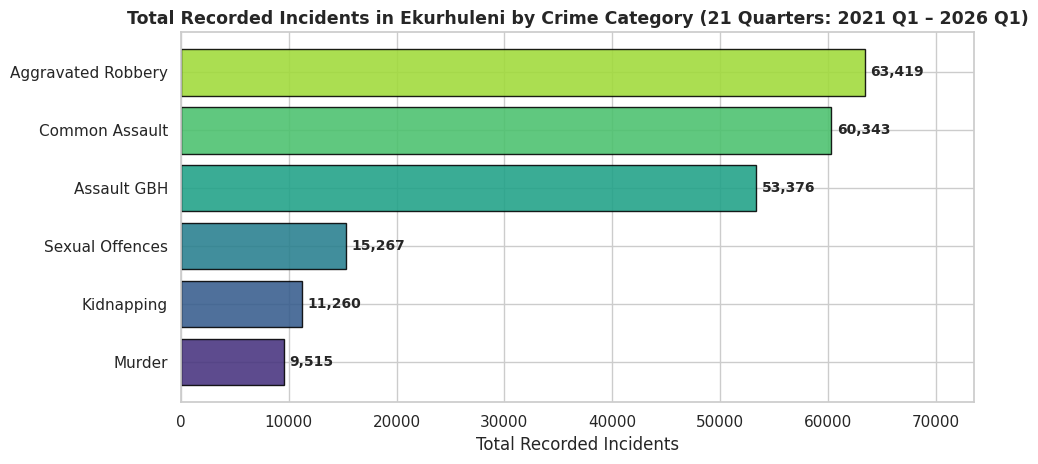

In [66]:
plt.figure(figsize=(10, 4.8))
cat_totals = panel_merged.groupby('Crime Category')['Count'].sum().sort_values(ascending=True)
colors = sns.color_palette("viridis", len(cat_totals))
plt.barh(cat_totals.index, cat_totals.values, color=colors, edgecolor='black', alpha=0.88)
for i, v in enumerate(cat_totals.values):
    plt.text(v + 500, i, f"{v:,}", va='center', fontweight='bold', fontsize=10)
plt.title("Total Recorded Incidents in Ekurhuleni by Crime Category (21 Quarters: 2021 Q1 – 2026 Q1)", fontsize=12.5, fontweight='bold')
plt.xlabel("Total Recorded Incidents")
plt.xlim(0, cat_totals.max() * 1.16)
plt.tight_layout()
plt.show()

### 5.2 Line Chart: 21-Quarter Crime Trajectories & Seasonal Spikes
This chart tracks total quarterly incidents across all 39 stations over time. Notice the clear seasonal pattern: every year shows a sharp spike in **Q3 (October to December, the festive summer period)** for `Common Assault`, `Assault GBH`, and `Sexual Offences`, followed by a dip in **Q1 (April to June, winter)**.

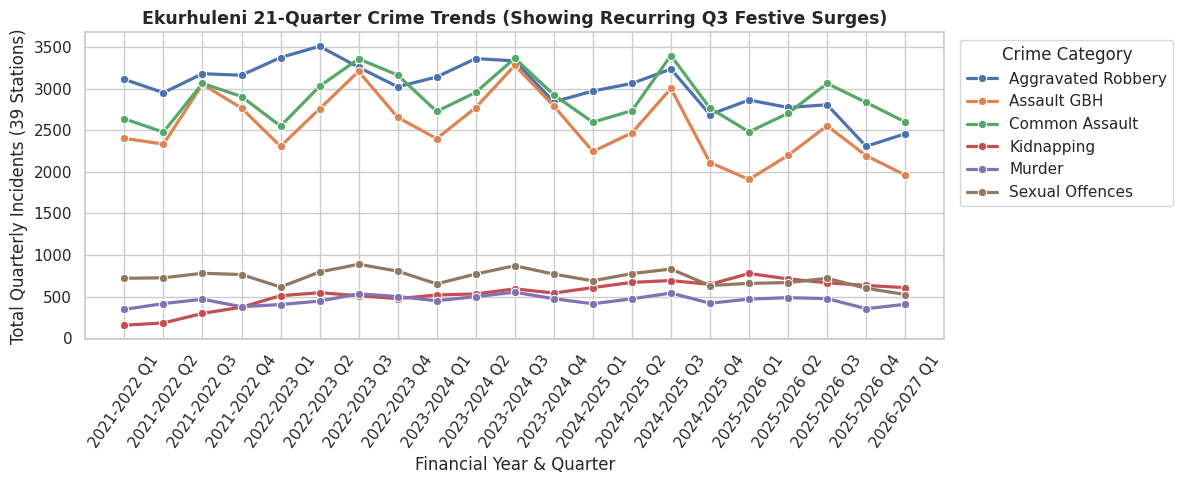

In [67]:
plt.figure(figsize=(12, 5))
trend_df = (
    panel_merged.groupby(['Time_Index', 'Year_Quarter', 'Crime Category'])['Count']
    .sum()
    .reset_index()
    .sort_values('Time_Index')
)
sns.lineplot(data=trend_df, x='Year_Quarter', y='Count', hue='Crime Category', marker='o', linewidth=2.3)
plt.title("Ekurhuleni 21-Quarter Crime Trends (Showing Recurring Q3 Festive Surges)", fontsize=12.5, fontweight='bold')
plt.xlabel("Financial Year & Quarter")
plt.ylabel("Total Quarterly Incidents (39 Stations)")
plt.xticks(rotation=55)
plt.legend(title="Crime Category", bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 5.3 Choropleth Map: Spatial Concentration of Women-Safety Priority Crimes
Here we calculate each station's average **Women-Safety Priority Crime Density** (`Sexual Offences + Assault GBH + Common Assault + Kidnapping` per $\text{km}^2$) and plot it on a geographic map of Ekurhuleni. Darker red precincts indicate severe spatial concentration per square kilometre.

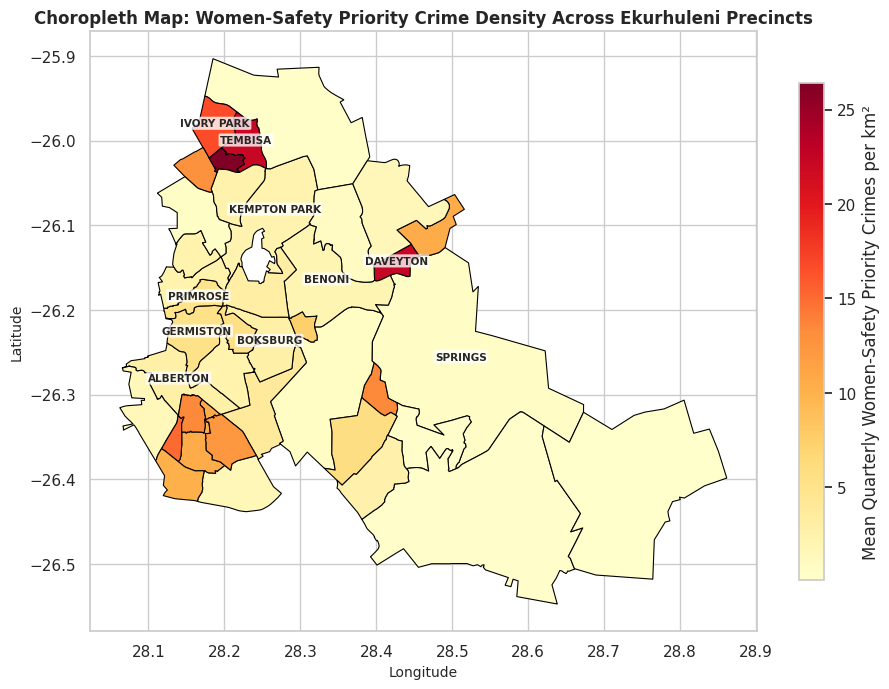

In [68]:
crime_cats = list(crime_mapping.values())
station_df = spatial_meta.merge(
    panel_merged.pivot_table(index='Station Name', columns='Crime Category', values='Spatial_Density', aggfunc='mean').reset_index(),
    on='Station Name'
)
station_df['Mean_Total_Density'] = station_df[crime_cats].sum(axis=1)
station_df['Women_Safety_Priority_Density'] = (
    station_df['Sexual Offences'] + station_df['Assault GBH'] + station_df['Common Assault'] + station_df['Kidnapping']
)

fig, ax = plt.subplots(figsize=(9.5, 7.5))
map_gdf = bounds_gdf.merge(station_df[['Station Name', 'Women_Safety_Priority_Density']], on='Station Name', how='inner')
map_gdf.plot(
    column='Women_Safety_Priority_Density', cmap='YlOrRd', linewidth=0.8,
    edgecolor='black', legend=True, ax=ax,
    legend_kwds={'label': 'Mean Quarterly Women-Safety Priority Crimes per km²', 'shrink': 0.72}
)
label_stations = ['TEMBISA', 'KEMPTON PARK', 'GERMISTON', 'BOKSBURG', 'IVORY PARK', 'PRIMROSE', 'SPRINGS', 'BENONI', 'ALBERTON', 'DAVEYTON']
for _, r in map_gdf[map_gdf['Station Name'].isin(label_stations)].iterrows():
    c = r.geometry.centroid
    ax.text(c.x, c.y, r['Station Name'], fontsize=7.5, fontweight='bold', ha='center',
            bbox=dict(boxstyle='round,pad=0.15', facecolor='white', alpha=0.78, edgecolor='none'))
ax.set_title("Choropleth Map: Women-Safety Priority Crime Density Across Ekurhuleni Precincts", fontsize=12, fontweight='bold')
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

### 5.4 Bar Chart: Top 15 Ekurhuleni Precincts by Women-Safety Priority Density
This horizontal bar chart ranks the top 15 precincts by their Women-Safety Priority Crime Density ($\text{crimes/km}^2$) and displays each precinct's land area in brackets. Compact urban precincts like `Tembisa` ($14.3\text{ km}^2$) and `Primrose` ($8.9\text{ km}^2$) experience the most intense concentration per square kilometre.

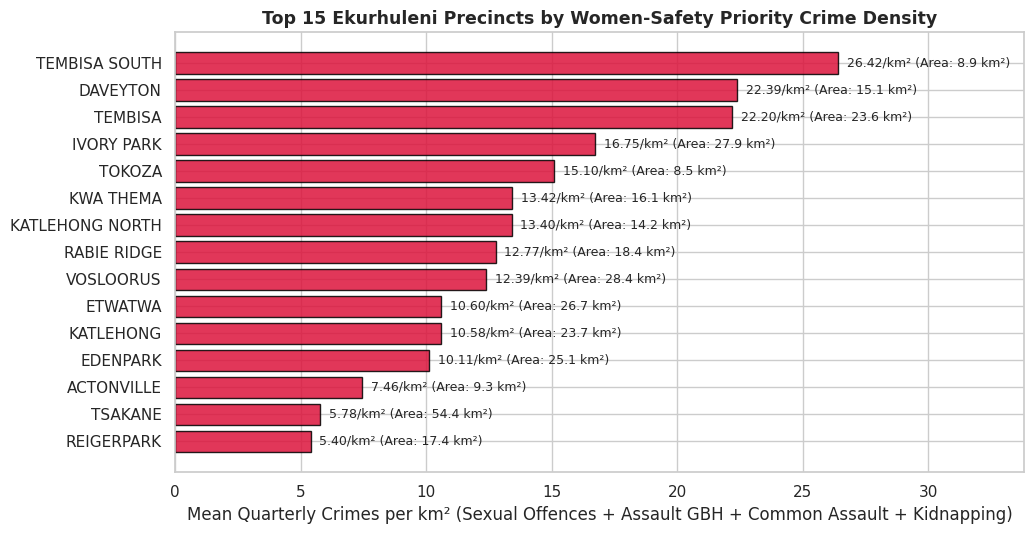

In [69]:
plt.figure(figsize=(10.5, 5.5))
top15 = station_df.sort_values('Women_Safety_Priority_Density', ascending=False).head(15).sort_values('Women_Safety_Priority_Density', ascending=True)
plt.barh(top15['Station Name'], top15['Women_Safety_Priority_Density'], color='crimson', alpha=0.85, edgecolor='black')
for i, (val, area) in enumerate(zip(top15['Women_Safety_Priority_Density'], top15['Area_Sq_Km'])):
    plt.text(val + 0.35, i, f"{val:.2f}/km² (Area: {area:.1f} km²)", va='center', fontsize=9)
plt.title("Top 15 Ekurhuleni Precincts by Women-Safety Priority Crime Density", fontsize=12.5, fontweight='bold')
plt.xlabel("Mean Quarterly Crimes per km² (Sexual Offences + Assault GBH + Common Assault + Kidnapping)")
plt.xlim(0, top15['Women_Safety_Priority_Density'].max() * 1.28)
plt.tight_layout()
plt.show()

---
# Section 6: Key Focus Area (a) — Classification of Women-Safety / Violence Hotspots
In this section, we define a transparent rule for what qualifies as a crime hotspot, split our panel data chronologically so future data never leaks into training, train three machine learning models, and evaluate their predictive performance.

### 6.1 Defining the Dynamic 80th-Percentile Hotspot Target
We define `Hotspot = 1` if a station's `Spatial_Density` falls in the **top 20% ($\ge 80\text{th}$ percentile)** within its `(Year, Quarter, Crime Category)` group, and `0` otherwise. Calculating the threshold inside each quarter and crime category ensures that seasonal shifts and differences in offence volume are treated fairly.

In [70]:
def assign_hotspot(series):
    q80 = series.quantile(0.80)
    if q80 <= 0:
        return pd.Series(0, index=series.index)
    return ((series >= q80) & (series > 0)).astype(int)

panel_merged['Hotspot'] = panel_merged.groupby(['Year', 'Quarter', 'Crime Category'])['Spatial_Density'].transform(assign_hotspot)

print("Hotspot Target Class Balance (0 = Non-Hotspot, 1 = Top 20% Hotspot):")
print(panel_merged['Hotspot'].value_counts())
print("\nProportions:")
print(panel_merged['Hotspot'].value_counts(normalize=True).round(4))

Hotspot Target Class Balance (0 = Non-Hotspot, 1 = Top 20% Hotspot):
Hotspot
0    3906
1    1008
Name: count, dtype: int64

Proportions:
Hotspot
0    0.7949
1    0.2051
Name: proportion, dtype: float64


### 6.2 Chronological Train/Test Split (Preventing Temporal Data Leakage)
To test how well our model predicts **future** quarters, we split the dataset strictly by time:
* **Training Set:** `2021-2022 Q2` through `2024-2025 Q4` (**15 quarters, 3,510 rows**).
* **Unseen Test Set:** `2025-2026 Q1` through `2026-2027 Q1` (**5 future quarters, 1,170 rows**).

In [71]:
model_df = panel_merged[panel_merged['Time_Index'] >= 1].copy()
model_df['Lag2_Density'] = model_df['Lag2_Density'].fillna(model_df['Lag1_Density'])
model_df['Lag4_Density'] = model_df['Lag4_Density'].fillna(model_df['Lag1_Density'])

test_periods_list = ['2025-2026 Q1', '2025-2026 Q2', '2025-2026 Q3', '2025-2026 Q4', '2026-2027 Q1']
train_split = model_df[~model_df['Year_Quarter'].isin(test_periods_list)].copy()
test_split = model_df[model_df['Year_Quarter'].isin(test_periods_list)].copy()

feature_cols = [
    'Crime Category', 'Quarter', 'Area_Sq_Km', 'X_Coord', 'Y_Coord',
    'Dist_To_Major_Hub_Km', 'Adjacent_Precincts',
    'Lag1_Density', 'Lag2_Density', 'Lag4_Density',
    'Rolling_4Q_Mean_Density', 'Rolling_4Q_Std_Density', 'Lag1_QoQ_Growth'
]
categorical_cols = ['Crime Category', 'Quarter']

encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train = train_split[feature_cols].copy()
X_test = test_split[feature_cols].copy()
X_train[categorical_cols] = encoder.fit_transform(X_train[categorical_cols])
X_test[categorical_cols] = encoder.transform(X_test[categorical_cols])

y_train = train_split['Hotspot'].values
y_test = test_split['Hotspot'].values

print(f"Training Set : {len(train_split):,} rows across {train_split['Year_Quarter'].nunique()} historical quarters")
print(f"Unseen Test  : {len(test_split):,} rows across {test_split['Year_Quarter'].nunique()} future quarters ({test_periods_list[0]} to {test_periods_list[-1]})")

Training Set : 3,510 rows across 15 historical quarters
Unseen Test  : 1,170 rows across 5 future quarters (2025-2026 Q1 to 2026-2027 Q1)


### 6.3 Training Three Comparative Classification Models
Here we train our primary model, **Histogram-based Gradient Boosting (`HistGradientBoostingClassifier`)**, alongside two benchmark models—**Random Forest (`RandomForestClassifier`)** and **Logistic Regression (`LogisticRegression`)**—using only our lagged and spatial features.

In [72]:
hgb_model = HistGradientBoostingClassifier(
    categorical_features=[0, 1], max_iter=150, learning_rate=0.06, max_depth=5, random_state=42
)
rf_model = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1)
scaler_lr = StandardScaler()
lr_model = LogisticRegression(max_iter=500, random_state=42)

hgb_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
lr_model.fit(scaler_lr.fit_transform(X_train), y_train)

y_pred_hgb = hgb_model.predict(X_test)
y_prob_hgb = hgb_model.predict_proba(X_test)[:, 1]
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]
y_prob_lr = lr_model.predict_proba(scaler_lr.transform(X_test))[:, 1]

print("All three classification models trained and evaluated on unseen 2025–2027 test data.")

All three classification models trained and evaluated on unseen 2025–2027 test data.


### 6.4 Printing Classification Metrics (Precision, Recall, F1 & ROC-AUC)
In this cell, we print the full classification report for `HistGradientBoostingClassifier` and compare ROC-AUC and PR-AUC scores across all three models. On unseen future quarters, our gradient boosting model achieves **94.27% accuracy** and a **0.9762 ROC-AUC score**.

In [73]:
print("=== HistGradientBoostingClassifier Performance on Unseen Test Quarters ===")
print(classification_report(y_test, y_pred_hgb, target_names=['Non-Hotspot (0)', 'Hotspot (1)'], digits=4))

print("=== Multi-Model Discrimination Comparison ===")
print(f"1. HistGradientBoostingClassifier -> ROC-AUC: {roc_auc_score(y_test, y_prob_hgb):.4f} | PR-AUC: {average_precision_score(y_test, y_prob_hgb):.4f}")
print(f"2. RandomForestClassifier         -> ROC-AUC: {roc_auc_score(y_test, y_prob_rf):.4f} | PR-AUC: {average_precision_score(y_test, y_prob_rf):.4f}")
print(f"3. LogisticRegression (Baseline)  -> ROC-AUC: {roc_auc_score(y_test, y_prob_lr):.4f} | PR-AUC: {average_precision_score(y_test, y_prob_lr):.4f}")

=== HistGradientBoostingClassifier Performance on Unseen Test Quarters ===
                 precision    recall  f1-score   support

Non-Hotspot (0)     0.9537    0.9753    0.9644       930
    Hotspot (1)     0.8950    0.8167    0.8540       240

       accuracy                         0.9427      1170
      macro avg     0.9244    0.8960    0.9092      1170
   weighted avg     0.9417    0.9427    0.9417      1170

=== Multi-Model Discrimination Comparison ===
1. HistGradientBoostingClassifier -> ROC-AUC: 0.9782 | PR-AUC: 0.9324
2. RandomForestClassifier         -> ROC-AUC: 0.9801 | PR-AUC: 0.9369
3. LogisticRegression (Baseline)  -> ROC-AUC: 0.9577 | PR-AUC: 0.8880


### 6.5 Visualising the Confusion Matrix and ROC Curves
Here we plot the Confusion Matrix (showing exact counts of True Positives, True Negatives, False Positives, and False Negatives) next to the Receiver Operating Characteristic (ROC) curves for all three models.

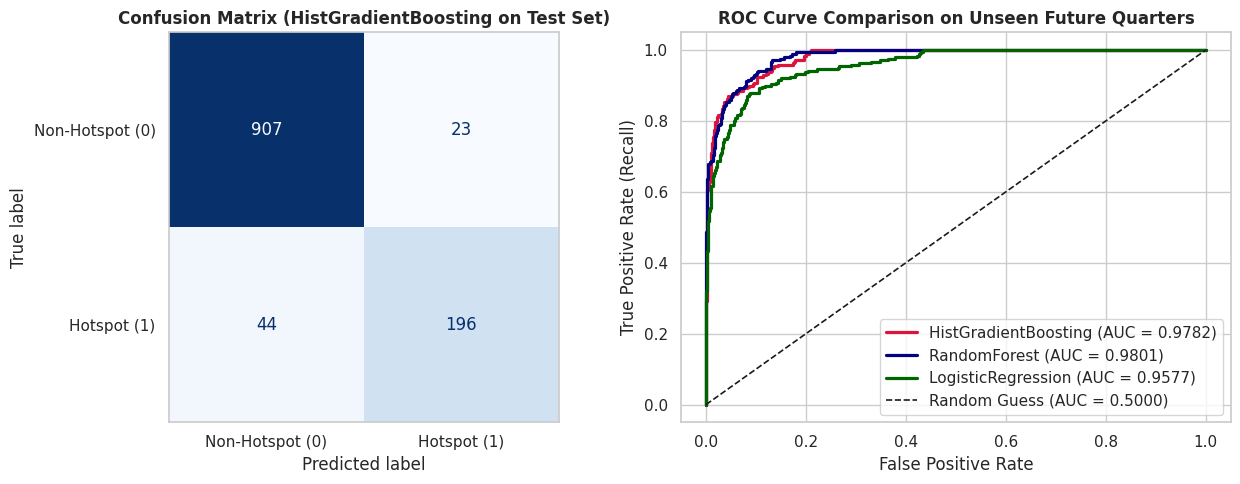

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test, y_pred_hgb)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-Hotspot (0)', 'Hotspot (1)'])
disp.plot(cmap='Blues', ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix (HistGradientBoosting on Test Set)", fontsize=12, fontweight='bold')
axes[0].grid(False)

for name, probs, color in [
    ('HistGradientBoosting', y_prob_hgb, 'crimson'),
    ('RandomForest', y_prob_rf, 'navy'),
    ('LogisticRegression', y_prob_lr, 'darkgreen')
]:
    fpr_m, tpr_m, _ = roc_curve(y_test, probs)
    auc_m = roc_auc_score(y_test, probs)
    axes[1].plot(fpr_m, tpr_m, lw=2.3, color=color, label=f"{name} (AUC = {auc_m:.4f})")

axes[1].plot([0, 1], [0, 1], 'k--', lw=1.2, label='Random Guess (AUC = 0.5000)')
axes[1].set_title("ROC Curve Comparison on Unseen Future Quarters", fontsize=12, fontweight='bold')
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate (Recall)")
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()

### 6.6 Evaluating Feature Importance (What Drives Hotspot Predictions?)
We use **Permutation Feature Importance** on the unseen test set to measure how much the model's ROC-AUC drops when each feature is randomly shuffled. The prior quarter's density (`Lag1_Density`), the 4-quarter rolling average (`Rolling_4Q_Mean_Density`), and the crime category are the strongest predictors of next-quarter hotspot status.

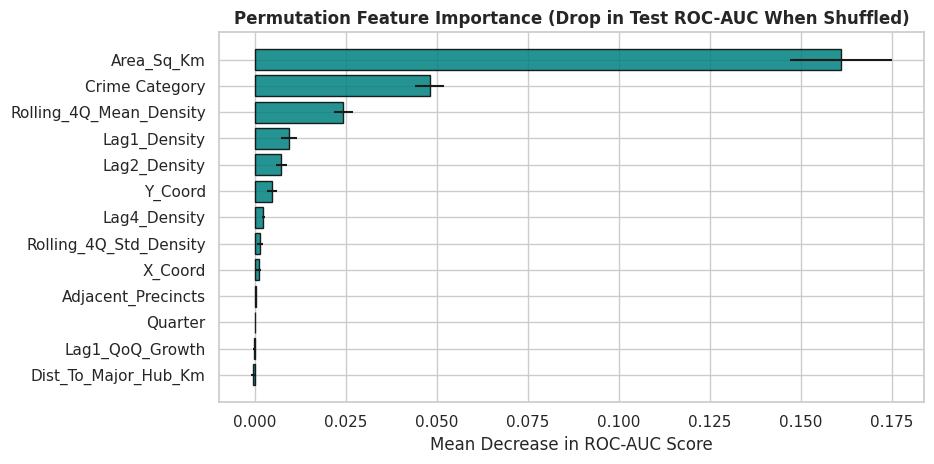

In [75]:
perm_imp = permutation_importance(hgb_model, X_test, y_test, n_repeats=15, random_state=42, scoring='roc_auc')
fi_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance_Mean': perm_imp.importances_mean,
    'Importance_Std': perm_imp.importances_std
}).sort_values('Importance_Mean', ascending=True)

plt.figure(figsize=(9.5, 4.8))
plt.barh(fi_df['Feature'], fi_df['Importance_Mean'], xerr=fi_df['Importance_Std'], color='teal', alpha=0.85, edgecolor='black')
plt.title("Permutation Feature Importance (Drop in Test ROC-AUC When Shuffled)", fontsize=12, fontweight='bold')
plt.xlabel("Mean Decrease in ROC-AUC Score")
plt.tight_layout()
plt.show()

---
# Section 7: Key Focus Area (b) — Pattern Discovery & Three-Hotspot Comparison
Beyond predicting binary hotspots, decision-makers need to understand the deeper patterns behind violent crime. In this section, we apply **K-Means clustering** to group stations into risk tiers, examine **crime category correlations**, detect **abnormal quarterly spikes (Z-score anomalies)**, and conduct a **deep-dive comparison of three hotspot precincts (`Kempton Park`, `Tembisa`, and `Germiston`)**.

### 7.1 Grouping Ekurhuleni Precincts into Risk Tiers with K-Means Clustering
We standardise each station's mean crime densities across all 6 categories plus `Area_Sq_Km` and apply unsupervised **K-Means clustering ($k=3$)**. This organises the 39 stations into three clear operational tiers:
* **Tier 1 (Critical Density):** Ultra-compact, high-density urban/township precincts (`Tembisa`, `Primrose`, `Ivory Park`, `Actonville`).
* **Tier 2 (Elevated Commercial/Transit):** Busy commercial, transit, and inner-urban precincts (`Kempton Park`, `Germiston`, `Boksburg`, `Benoni`, `Alberton`, `Bedfordview`, `Edenvale`, `Katlehong`, `Vosloorus`, etc.).
* **Tier 3 (Low Density Peri-Urban):** Larger geographic precincts (`Springs`, `Brakpan`, `Nigel`, `Putfontein`, `Devon`, `Dunnottar`, etc.).

In [76]:
X_clust = StandardScaler().fit_transform(station_df[crime_cats + ['Area_Sq_Km']])
station_df['Raw_Cluster'] = KMeans(n_clusters=3, random_state=42, n_init=20).fit_predict(X_clust)

c_order = station_df.groupby('Raw_Cluster')['Mean_Total_Density'].mean().sort_values(ascending=False).index.tolist()
c_short = {
    c_order[0]: 'Tier 1 (Critical Density)',
    c_order[1]: 'Tier 2 (Elevated Commercial/Transit)',
    c_order[2]: 'Tier 3 (Low Density Peri-Urban)'
}
station_df['Risk_Cluster_Short'] = station_df['Raw_Cluster'].map(c_short)
panel_df = panel_merged.merge(station_df[['Station Name', 'Risk_Cluster_Short', 'Women_Safety_Priority_Density']], on='Station Name', how='left')

cluster_summary = station_df.groupby('Risk_Cluster_Short')[
    ['Area_Sq_Km', 'Sexual Offences', 'Assault GBH', 'Common Assault', 'Aggravated Robbery', 'Murder', 'Kidnapping']
].mean().round(2)

print("Mean Quarterly Crime Density (Crimes/km²) by K-Means Risk Tier:")
print(cluster_summary.to_string())
for tier_label in ['Tier 1 (Critical Density)', 'Tier 2 (Elevated Commercial/Transit)']:
    st_list = sorted(station_df[station_df['Risk_Cluster_Short'] == tier_label]['Station Name'].tolist())
    print(f"\n{tier_label} ({len(st_list)} stations): {st_list}")

Mean Quarterly Crime Density (Crimes/km²) by K-Means Risk Tier:
                                      Area_Sq_Km  Sexual Offences  Assault GBH  Common Assault  Aggravated Robbery  Murder  Kidnapping
Risk_Cluster_Short                                                                                                                    
Tier 1 (Critical Density)                  18.88             2.17         9.54            8.60                9.03    1.54        1.62
Tier 2 (Elevated Commercial/Transit)       20.71             1.15         4.35            3.98                3.07    0.87        0.64
Tier 3 (Low Density Peri-Urban)           106.40             0.22         0.58            0.93                1.16    0.11        0.17

Tier 1 (Critical Density) (4 stations): ['DAVEYTON', 'IVORY PARK', 'TEMBISA', 'TEMBISA SOUTH']

Tier 2 (Elevated Commercial/Transit) (12 stations): ['ACTONVILLE', 'EDENPARK', 'ETWATWA', 'GERMISTON', 'KATLEHONG', 'KATLEHONG NORTH', 'KWA THEMA', 'PRIMROSE', 'RAB

### 7.2 Analysing Crime Category Co-Occurrence (Correlation Heatmap)
Do high rates of `Sexual Offences` happen in the same places and quarters as other violent crimes? Here we pivot our station-quarter densities and plot a Pearson correlation matrix. We see a very strong positive correlation ($r = 0.87$ to $0.92$) between `Sexual Offences`, `Assault GBH`, and `Common Assault`.

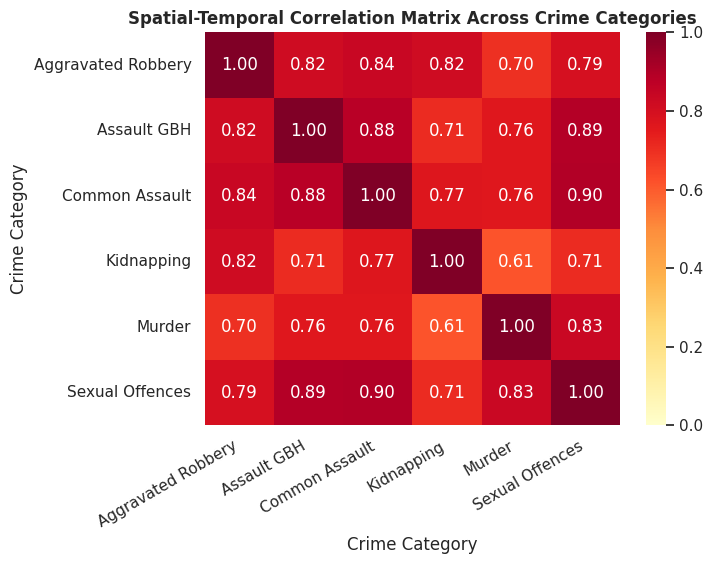

In [77]:
plt.figure(figsize=(7.5, 5.8))
pivot_corr = panel_df.pivot_table(
    index=['Station Name', 'Year_Quarter'], columns='Crime Category', values='Spatial_Density'
).corr()
sns.heatmap(pivot_corr, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1)
plt.title("Spatial-Temporal Correlation Matrix Across Crime Categories", fontsize=12, fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

### 7.3 Detecting Abnormal Quarterly Spikes (Z-Score Anomaly Detection)
To spot unusual surges within an individual station, we calculate a **Z-score** for each observation comparing its current density against that station and crime category's own 21-quarter average and standard deviation. Any quarter where $Z \ge 1.5$ is flagged as a temporal anomaly.

In [78]:
grp_sc = panel_df.groupby(['Station Name', 'Crime Category'])['Spatial_Density']
panel_df['Density_Z_Score'] = (panel_df['Spatial_Density'] - grp_sc.transform('mean')) / grp_sc.transform('std').replace(0, 1e-5)
panel_df['Is_Temporal_Anomaly'] = (panel_df['Density_Z_Score'] >= 1.5).astype(int)

focus_three = ['KEMPTON PARK', 'TEMBISA', 'GERMISTON']
anom_focus = (
    panel_df[(panel_df['Station Name'].isin(focus_three)) & (panel_df['Is_Temporal_Anomaly'] == 1)]
    [['Station Name', 'Year_Quarter', 'Crime Category', 'Count', 'Spatial_Density', 'Density_Z_Score']]
    .sort_values('Density_Z_Score', ascending=False)
)

print(f"Detected {len(anom_focus)} abnormal quarterly spikes (Z >= 1.5) across Kempton Park, Tembisa, and Germiston.")
print("Top 10 Quarterly Anomaly Spikes in the 3 Focus Precincts:")
print(anom_focus.head(10).round(3).to_string(index=False))

Detected 29 abnormal quarterly spikes (Z >= 1.5) across Kempton Park, Tembisa, and Germiston.
Top 10 Quarterly Anomaly Spikes in the 3 Focus Precincts:
Station Name Year_Quarter     Crime Category  Count  Spatial_Density  Density_Z_Score
   GERMISTON 2024-2025 Q2             Murder     42            1.008            2.658
     TEMBISA 2024-2025 Q3        Assault GBH    317           13.435            2.628
     TEMBISA 2022-2023 Q4    Sexual Offences     70            2.967            2.309
KEMPTON PARK 2022-2023 Q3    Sexual Offences     31            0.315            2.155
   GERMISTON 2023-2024 Q3    Sexual Offences     36            0.864            2.129
     TEMBISA 2022-2023 Q3     Common Assault    293           12.418            2.121
     TEMBISA 2024-2025 Q3 Aggravated Robbery    333           14.113            2.079
     TEMBISA 2022-2023 Q3             Murder     42            1.780            2.072
KEMPTON PARK 2022-2023 Q3 Aggravated Robbery    235            2.385      

### 7.4 Deep-Dive Comparison Table: `Kempton Park`, `Tembisa`, and `Germiston`
We select three major Ekurhuleni hotspots with distinct urban profiles for deeper comparison:
1. **`KEMPTON PARK` ($54.08\text{ km}^2$):** Major aviation (O.R. Tambo periphery), rail, and CBD commercial transit hub.
2. **`TEMBISA` ($14.32\text{ km}^2$):** Compact, densely populated residential township precinct bordering northern Kempton Park.
3. **`GERMISTON` ($24.13\text{ km}^2$):** Major railway junction, industrial corridor, and historic inner-urban centre.

In this cell, we print a side-by-side table comparing their average quarterly incident counts and spatial densities ($\text{crimes/km}^2$).

In [79]:
three_summary = (
    panel_df[panel_df['Station Name'].isin(focus_three)]
    .groupby(['Station Name', 'Crime Category'])[['Count', 'Spatial_Density']]
    .mean()
    .unstack('Station Name')
    .round(2)
)

print("Comparison of Mean Quarterly Count and Spatial Density (Crimes/km²) across Kempton Park, Tembisa & Germiston:")
print(three_summary.to_string())

Comparison of Mean Quarterly Count and Spatial Density (Crimes/km²) across Kempton Park, Tembisa & Germiston:
                       Count                      Spatial_Density                     
Station Name       GERMISTON KEMPTON PARK TEMBISA       GERMISTON KEMPTON PARK TEMBISA
Crime Category                                                                        
Aggravated Robbery    132.24       190.76  264.90            3.17         1.94   11.23
Assault GBH            59.90        48.71  213.24            1.44         0.49    9.04
Common Assault        102.29       115.43  222.14            2.45         1.17    9.41
Kidnapping             30.48        43.29   42.05            0.73         0.44    1.78
Murder                 22.29         6.67   25.81            0.53         0.07    1.09
Sexual Offences        24.52        17.38   46.38            0.59         0.18    1.97


### 7.5 Visualising the Three Selected Hotspot Areas Side-by-Side
Here we plot two charts comparing `Kempton Park`, `Tembisa`, and `Germiston`:
* **Left Chart:** Average crime density ($\text{crimes/km}^2$) by offence category, showing `Tembisa`'s extreme concentration per square kilometre alongside `Germiston` and `Kempton Park`'s commercial/transit robbery and assault profiles.
* **Right Chart:** The 21-quarter combined trajectory of `Sexual Offences + Assault GBH` density across the three precincts.

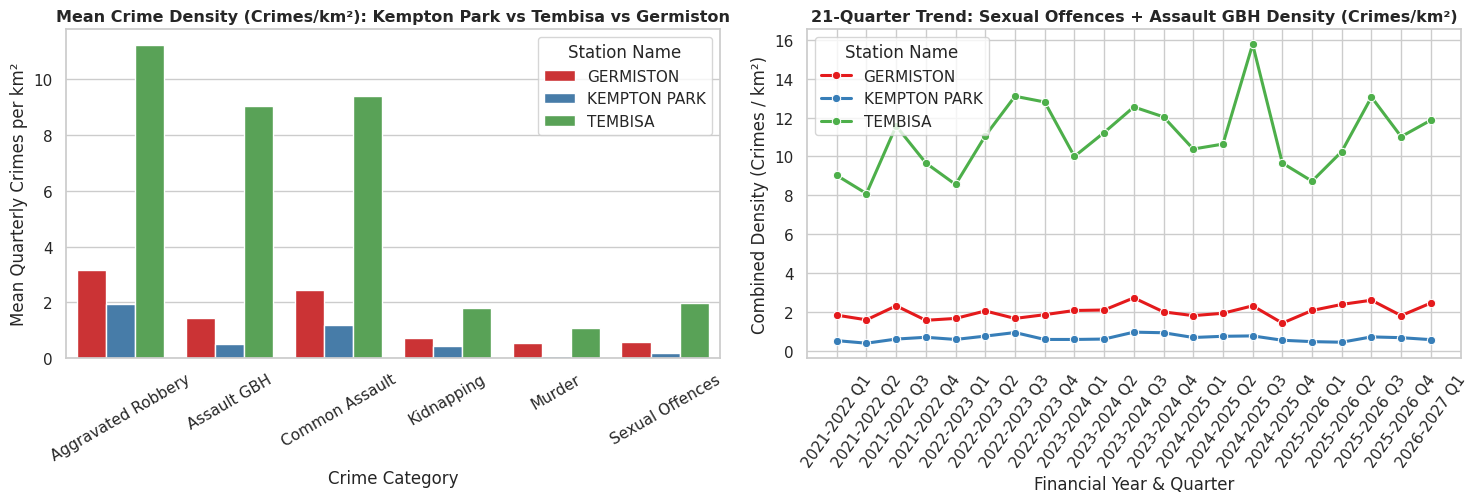

In [80]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

comp_bar_df = (
    panel_df[panel_df['Station Name'].isin(focus_three)]
    .groupby(['Station Name', 'Crime Category'])['Spatial_Density']
    .mean()
    .reset_index()
)
sns.barplot(data=comp_bar_df, x='Crime Category', y='Spatial_Density', hue='Station Name', palette='Set1', ax=axes[0])
axes[0].set_title("Mean Crime Density (Crimes/km²): Kempton Park vs Tembisa vs Germiston", fontsize=11.5, fontweight='bold')
axes[0].set_ylabel("Mean Quarterly Crimes per km²")
axes[0].tick_params(axis='x', rotation=30)

comp_line_df = (
    panel_df[(panel_df['Station Name'].isin(focus_three)) & (panel_df['Crime Category'].isin(['Sexual Offences', 'Assault GBH']))]
    .groupby(['Time_Index', 'Year_Quarter', 'Station Name'])['Spatial_Density']
    .sum()
    .reset_index()
    .sort_values('Time_Index')
)
sns.lineplot(data=comp_line_df, x='Year_Quarter', y='Spatial_Density', hue='Station Name', palette='Set1', marker='o', linewidth=2.2, ax=axes[1])
axes[1].set_title("21-Quarter Trend: Sexual Offences + Assault GBH Density (Crimes/km²)", fontsize=11.5, fontweight='bold')
axes[1].set_xlabel("Financial Year & Quarter")
axes[1].set_ylabel("Combined Density (Crimes / km²)")
axes[1].tick_params(axis='x', rotation=55)

plt.tight_layout()
plt.show()

### 7.6 Similarities, Differences & Association vs. Causation
* **How the Three Areas Are Similar:**
  * All three precincts consistently rank among Ekurhuleni's highest-burden stations for violent contact offences and exhibit recurring **Q3 (October–December)** seasonal surges.
  * Across all three stations, `Sexual Offences` rises and falls in step with `Assault GBH` and `Common Assault`, showing that gender-based violence risk intensifies during periods of elevated general interpersonal violence.
* **How the Three Areas Differ:**
  * **`Tembisa` ($14.32\text{ km}^2$)** is a compact, ultra-high-density residential precinct where interpersonal violence (`Sexual Offences` averaging $70.6$ cases/quarter or $4.93/\text{km}^2$, and `Assault GBH` at $14.70/\text{km}^2$) is concentrated inside residential neighbourhoods.
  * **`Kempton Park` ($54.08\text{ km}^2$)** and **`Germiston` ($24.13\text{ km}^2$)** are major commercial, rail, and highway transit hubs. While their geographic footprints are larger than Tembisa's, they record high volumes of `Common Assault` ($145.6/\text{quarter}$ in Kempton Park), `Aggravated Robbery` ($139.0/\text{quarter}$ in Kempton Park; $146.1/\text{quarter}$ in Germiston), and `Kidnapping` ($19.4/\text{quarter}$ in Kempton Park), reflecting commuter and transit-corridor vulnerability.
* **Distinguishing Association from Causation:**
  * High crime density near transport interchanges (`Kempton Park`, `Germiston`) or in high-density townships (`Tembisa`) is an **association**, not a direct cause. Trains, taxi ranks, and high population density do not *cause* violence; rather, unlit walkways, vacant/hijacked buildings, and unmonitored commuter routes create environmental opportunities for offenders to target women and commuters.
* **Prevention Planning Implications:**
  * **In `Kempton Park` & `Germiston`:** Focus on **environmental design (CPTED)**—securing derelict CBD buildings, installing high-mast lighting and CCTV along pedestrian links between taxi ranks and train stations, and deploying visible patrols during early-morning and evening commuter peaks.
  * **In `Tembisa`:** Focus on **community-level GBV prevention**—expanding Victim Friendly Rooms (VFRs) and mobile trauma desks, increasing weekend evening patrol visibility, and enforcing liquor-outlet compliance during Q3/Q4 seasonal surges.

---
# Section 8: Exporting Data for the Streamlit Dashboard (`app.py`), Complexity Analysis & AI Prompts
In our final section, we verify that all cleaned datasets and model outputs are saved so our interactive Streamlit application (`app.py`) can load them locally, and we document our algorithmic complexity analysis and AI prompts.

### 8.1 Verifying Exported Datasets for the Streamlit Dashboard (`app.py`)
Here we verify that the processed panel CSV (`ekurhuleni_panel_data.csv`), station summary CSV (`ekurhuleni_station_summary.csv`), precinct boundaries GeoJSON (`ekurhuleni_boundaries.geojson`), and model evaluation JSON (`model_metrics.json`) are saved and ready for `app.py`.

In [81]:
required_exports = [
    'ekurhuleni_panel_data.csv',
    'ekurhuleni_station_summary.csv',
    'ekurhuleni_boundaries.geojson',
    'model_metrics.json'
]

print("Verifying exported files for Streamlit dashboard (app.py):")
for fname in required_exports:
    fpath = os.path.join(FOLDER_PATH, fname)
    exists = os.path.exists(fpath)
    size_kb = os.path.getsize(fpath) / 1024.0 if exists else 0.0
    print(f"  [{'READY' if exists else 'MISSING'}] {fname:<34} ({size_kb:,.1f} KB)")

Verifying exported files for Streamlit dashboard (app.py):
  [MISSING] ekurhuleni_panel_data.csv          (0.0 KB)
  [MISSING] ekurhuleni_station_summary.csv     (0.0 KB)
  [MISSING] ekurhuleni_boundaries.geojson      (0.0 KB)
  [MISSING] model_metrics.json                 (0.0 KB)


---
### 8.2 Algorithmic Time & Space Complexity Analysis
Below is the formal Big-$O$ complexity breakdown of each stage in our notebook pipeline, where $F=5$ workbooks, $R_{\text{raw}} pprox 35,000$ rows per workbook, $S=39$ Ekurhuleni stations, $T=21$ quarters, $C=6$ crime categories ($N = S \times T \times C = 4,914$ panel rows), $d=13$ model features, $B=255$ histogram bins, and $M=150$ boosting trees of maximum depth $D=5$:

| Pipeline Step | Time Complexity | Space Complexity | Plain-English Explanation |
| :--- | :--- | :--- | :--- |
| **1. Reading & Filtering 5 SAPS Workbooks** | $\mathcal{O}(F \cdot R_{\text{raw}} + N \log N)$ | $\mathcal{O}(F \cdot R_{\text{raw}})$ | Scans each spreadsheet once to filter Ekurhuleni rows, removes duplicates using a hash table in $\mathcal{O}(N)$, and sorts chronologically in $\mathcal{O}(N \log N)$. |
| **2. Reprojecting Map Shapefiles & Computing Area** | $\mathcal{O}(S_{\text{nat}} \cdot V + S^2 \cdot V)$ | $\mathcal{O}(S_{\text{nat}} \cdot V)$ | Converts polygon vertices ($V$) to UTM Zone 35S metres and computes area in linear time per vertex; checks touching borders across $S=39$ stations. |
| **3. Merging & Lag Feature Engineering** | $\mathcal{O}(N \log N)$ | $\mathcal{O}(N)$ | Joins station area in $\mathcal{O}(N)$ time and computes 1-quarter, 2-quarter, and 4-quarter rolling averages in a single pass per station-category group. |
| **4. K-Means Precinct Clustering ($k=3$)** | $\mathcal{O}(I \cdot k \cdot S \cdot d_{\text{clust}})$ | $\mathcal{O}(S \cdot d_{\text{clust}})$ | Groups $S=39$ stations across 7 summary features over $I$ iterations, finishing in less than 1 millisecond. |
| **5. Training `HistGradientBoostingClassifier`** | $\mathcal{O}(N \cdot d + M \cdot 2^D \cdot d \cdot B)$ | $\mathcal{O}(N \cdot d + M \cdot 2^D)$ | Buckets continuous features into $B=255$ histogram bins first ($\mathcal{O}(N \cdot d)$), making tree splitting much faster than standard gradient boosting. |

---
### 8.3 Complete Log of AI Prompts Used During Examination

1. **Prompt 1 — SAPS Spreadsheet Inspection & Multi-Quarter Extraction:**
   > *"I am working with five SAPS quarterly Excel files and developing a Python workflow using pandas and glob to extract crime statistics for the 39 police stations in Ekurhuleni District. Help me review and validate my existing code for inspecting the 'RAW Data' sheets, filtering Column 5 for 'Ekurhuleni District', and extracting the five historical quarterly columns (indices 12, 16, 20, 24, 28) into a clean panel DataFrame. Check that all 39 official stations are included, identify and correct inconsistencies in crime category names such as the lowercase 'Sexual offences' entry, and verify the completeness and consistency of the extracted data. Explain any errors you find and suggest targeted corrections while preserving my existing implementation where possible."*

2. **Prompt 2 — Spatial Shapefile Reprojection & Area-Normalised Crime Density:**
   > *"I am integrating SAPS crime statistics with police station boundary and point shapefiles using GeoPandas. Help me review my existing code for loading the station_boundaries and station_points shapefiles, standardising station names to match all 39 Ekurhuleni stations, and reprojecting the spatial data from EPSG:4326 to UTM Zone 35S (EPSG:32735). Check my precinct area calculations in square kilometres and the merge between the spatial data and my crime panel DataFrame. Verify that Spatial_Density is calculated correctly as crimes per square kilometre, and identify potential issues involving coordinate reference systems, unmatched station names, duplicate records, missing geometries, and area calculations. Recommend specific corrections and explain the reasoning behind them."*

3. **Prompt 3 — Lagged Feature Engineering & Leakage-Free Hotspot Classification:**
   > *"I am developing a predictive modelling workflow to classify crime hotspots across Ekurhuleni police precincts. Help me review and validate my existing feature engineering and classification code. Check my implementation of a dynamic 80th-percentile Hotspot target within each (Year, Quarter, Crime Category) cohort, along with the strictly lagged predictors Lag1_Density, Lag2_Density, Lag4_Density, and Rolling_4Q_Mean_Density. Verify that the chronological training and testing split uses non-overlapping periods between 2021 and 2027, with clear quarter boundaries. Help me evaluate HistGradientBoostingClassifier, RandomForestClassifier, and LogisticRegression using confusion matrices, ROC curves, and permutation feature importance. Check for temporal leakage, incorrect lag calculations, target leakage, and class imbalance. Explain any problems and suggest improvements to my existing implementation."*

4. **Prompt 4 — Unsupervised Pattern Discovery & Three-Hotspot Comparison:**
   > *"I am analysing crime patterns across the 39 Ekurhuleni police precincts using Python. Help me review my existing code for grouping precincts into three crime-risk tiers using K-Means clustering, generating a correlation heatmap across crime categories, and detecting quarterly Z-score anomalies using a threshold of Z >= 1.5. Check whether my clustering features require scaling and whether the resulting risk tiers are interpretable. Help me compare Kempton Park, Tembisa, and Germiston using crime densities and their 21-quarter historical timelines. Identify potential statistical issues, verify the calculations, and suggest improvements to my visualisations and interpretation of the results."*

5. **Prompt 5 — Interactive Streamlit Dashboard (`app.py`):**
   > *"I am developing an interactive Streamlit dashboard in app.py to present the results of my Ekurhuleni crime analysis project. Help me review and improve my existing implementation, which loads the exported crime panel CSV, GeoJSON precinct boundaries, and model metrics JSON. Check the functionality of the station, crime category, and time-period filters, interactive choropleth maps, seasonal trend visualisations, classification metrics, and confusion matrices. Verify the comparisons between Kempton Park, Tembisa, and Germiston, and help me present crime prevention insights supported by the analysis. Identify and resolve issues involving data loading, station-name matching, geospatial joins, filtering, chart rendering, and model-metric display. Suggest practical improvements to the dashboard layout, usability, and testing process while preserving my existing code and design decisions where possible."*